# Player Archetypes — training notebook

Trains K-Means **once, offline**, on a simulated player population whose per-game hours and
library sizes are calibrated on the public **Steam 200k** dataset. The frozen model is exported
later (Step 5) and served by the Python service, which assigns each real user to the nearest centre.

Every player — simulated here, real in the app — goes through the same
`archetype_features.compute_features`, so training and serving use identical features.

Runs locally (from `notebooks/`) or in Google Colab. Edit the paths in the first cell.

In [1]:
# --- Paths: edit these --------------------------------------------------------
REPO_URL  = "https://github.com/aljoharas/2026-GP1-Group8.git"
REPO_BRANCH = "feature/player-archetypes"
USE_DRIVE = False                                          # True: read the CSV from Google Drive
DRIVE_CSV = "/content/drive/MyDrive/loadout/steam-200k.csv"
SEED = 42

import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO_DIR = Path("/content/2026-GP1-Group8")
    if not REPO_DIR.exists():
        !git clone -q -b {REPO_BRANCH} {REPO_URL} {REPO_DIR}
    if USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
else:
    REPO_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# data/ is gitignored: in Colab without Drive, upload the CSV to this path
STEAM_CSV = Path(DRIVE_CSV) if USE_DRIVE else REPO_DIR / "data" / "steam-200k.csv"
DATA_DIR = REPO_DIR / "data"
FIGURES = REPO_DIR / "notebooks" / "figures"
DATA_DIR.mkdir(exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(REPO_DIR / "backend" / "recommender"))
print("repo:", REPO_DIR, "| csv:", STEAM_CSV, "| exists:", STEAM_CSV.exists())

repo: /Users/aljoharaalsultan/Development/2026-GP1-Group8 | csv: /Users/aljoharaalsultan/Development/2026-GP1-Group8/data/steam-200k.csv | exists: True


In [2]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

import archetype_sim as sim
from archetype_features import FEATURE_NAMES, IMPUTED_FEATURES, MIN_GAMES, compute_features

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

# Chart style: one surface, recessive axes, a fixed categorical order
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
MIXED = "#a3a29b"   # mixed players are not a persona, so they stay gray
DIVERGING = LinearSegmentedColormap.from_list("blue_red", ["#1c5cab", "#86b6ef", "#f0efec", "#f09a99", "#c23a3a"])
PERSONA_COLORS = {**dict(zip(sim.PERSONA_NAMES, SERIES)), "mixed": MIXED}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.size": 10, "legend.frameon": False, "figure.dpi": 100,
})

def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 1. Steam 200k — calibration data

Keep only `play` rows with hours > 0, summed per (user, game). Per-game hours are capped at the
99th percentile of all plays (Steam counts idle time). The generator samples from users with
**≥ 5 played games**, the only players the model scores.

In [3]:
plays = sim.load_steam_plays(STEAM_CSV)
cal = sim.steam_calibration(plays)

library_all = plays.groupby("user_id").size()
hours_by_game = plays.groupby("game")["hours"].sum().sort_values(ascending=False)
players_by_game = plays["game"].value_counts()

facts = pd.Series({
    "(user, game) plays with hours > 0": len(plays),
    "users with any play": len(library_all),
    "median per-game hours (all plays)": plays["hours"].median(),
    "90th pct per-game hours (all plays)": plays["hours"].quantile(0.90),
    "99th pct = cap": cal["cap"],
    "median games played per user (all users)": library_all.median(),
    "users with >= 5 played games": len(cal["library_sizes"]),
    "median per-game hours (users >= 5, capped)": np.median(cal["hours"]),
    "90th pct per-game hours (users >= 5, capped)": np.quantile(cal["hours"], 0.90),
    "median library (users >= 5)": np.median(cal["library_sizes"]),
    "most-played game by hours": hours_by_game.index[0],
    "its share of all hours": hours_by_game.iloc[0] / hours_by_game.sum(),
    "most-played game by players": players_by_game.index[0],
}, dtype=object)
facts

(user, game) plays with hours > 0                  70477
users with any play                                11350
median per-game hours (all plays)                    4.5
90th pct per-game hours (all plays)                 76.0
99th pct = cap                                     908.0
median games played per user (all users)             1.0
users with >= 5 played games                        2436
median per-game hours (users >= 5, capped)           4.4
90th pct per-game hours (users >= 5, capped)        64.0
median library (users >= 5)                         12.0
most-played game by hours                         Dota 2
its share of all hours                          0.284929
most-played game by players                       Dota 2
dtype: object

**Known facts confirmed:** median per-game hours ≈ 4.5h and 90th percentile ≈ 76h over all plays;
the median user plays **1** game; about 2,400 users have ≥ 5 games; Dota 2 dominates by both hours
and player count (free-to-play / online skew, PC only).

In [4]:
# Save the empirical distributions the generator samples from
pd.Series(cal["hours"], name="hours").to_csv(DATA_DIR / "steam_game_hours.csv", index=False)
pd.Series(cal["library_sizes"], name="games_played").to_csv(DATA_DIR / "steam_library_sizes.csv", index=False)

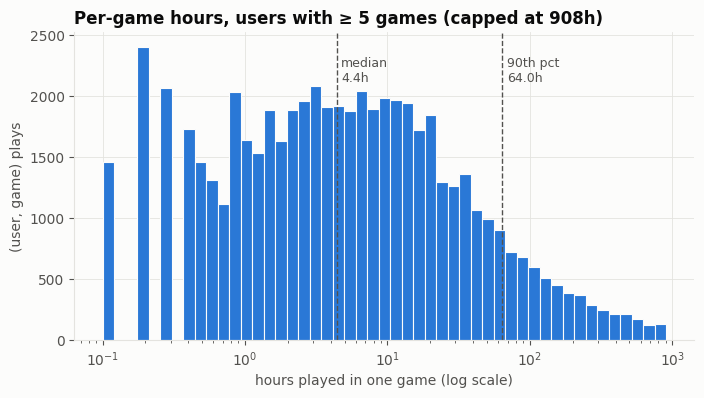

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.logspace(np.log10(cal["hours"].min()), np.log10(cal["cap"]), 50)
ax.hist(cal["hours"], bins=bins, color=SERIES[0], edgecolor=SURFACE, linewidth=0.8)
ax.set_xscale("log")
for q, label in [(0.5, "median"), (0.9, "90th pct")]:
    v = np.quantile(cal["hours"], q)
    ax.axvline(v, color=INK2, linewidth=1, linestyle="--")
    ax.text(v * 1.08, ax.get_ylim()[1] * 0.92, f"{label}\n{v:.1f}h", color=INK2, fontsize=9, va="top")
ax.set_title(f"Per-game hours, users with ≥ 5 games (capped at {cal['cap']:.0f}h)")
ax.set_xlabel("hours played in one game (log scale)")
ax.set_ylabel("(user, game) plays")
save(fig, "01_steam_game_hours")

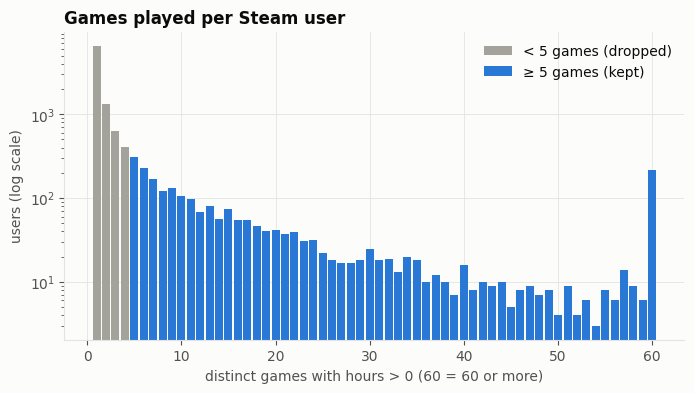

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
sizes = library_all.clip(upper=60).value_counts().sort_index()
kept = sizes.index >= MIN_GAMES
ax.bar(sizes.index[~kept], sizes[~kept], width=0.85, color=MIXED, label="< 5 games (dropped)")
ax.bar(sizes.index[kept], sizes[kept], width=0.85, color=SERIES[0], label="≥ 5 games (kept)")
ax.set_yscale("log")
ax.set_title("Games played per Steam user")
ax.set_xlabel("distinct games with hours > 0 (60 = 60 or more)")
ax.set_ylabel("users (log scale)")
ax.legend(loc="upper right")
save(fig, "02_steam_library_sizes")

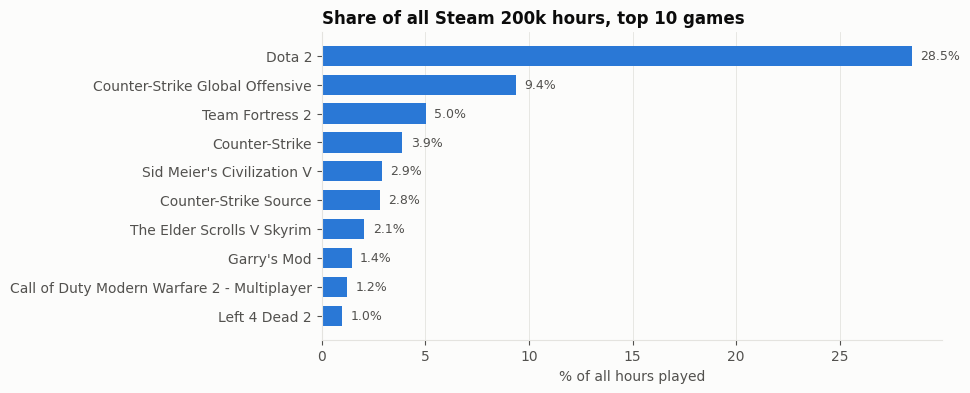

In [7]:
top = (hours_by_game.head(10) / hours_by_game.sum() * 100)[::-1]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(top.index, top.values, color=SERIES[0], height=0.7)
for y, v in enumerate(top.values):
    ax.text(v + 0.4, y, f"{v:.1f}%", va="center", color=INK2, fontsize=9)
ax.set_title("Share of all Steam 200k hours, top 10 games")
ax.set_xlabel("% of all hours played")
ax.grid(axis="y", visible=False)
save(fig, "03_steam_top_games")

## 2. Simulated players → features → imputation → scaling

`generate_players` draws each player's **games** (hours, statuses, trophies, genres, online
flag, months); the features are then computed by the shared `compute_features`, never drawn directly.
All persona parameters are in `archetype_sim.PERSONAS`. 25% of the population are mixed
players (each game drawn from persona A with probability w ~ U(0.3, 0.7), else from B).

In [8]:
pd.DataFrame(sim.PERSONAS).T

,library_size,hours_quantiles,top_game_quantiles,completion_beta,trophy_beta,favourite_genres,favourite_share,online_beta,active_months
completionist,"(5, 15)","(0.25, 0.9)",None,"(8, 2)","(6, 4)","(3, 4)",0.7,"(2, 5)","(6, 12)"
explorer,"(10, 40)","(0.05, 0.6)",None,"(2.5, 4)","(2, 6)","(12, 12)",1.0,"(2, 5)","(6, 12)"
devotee,"(5, 10)","(0.05, 0.5)","(0.95, 0.995)","(3, 4)","(2, 6)","(1, 2)",0.85,"(2, 5)","(6, 12)"
competitor,"(5, 15)","(0.4, 0.95)",None,"(3, 4)","(2, 6)","(3, 4)",0.7,"(8, 2)","(6, 12)"
casual,"(5, 8)","(0.05, 0.5)",None,"(2, 4)","(2, 6)","(3, 4)",0.7,"(2, 5)","(2, 5)"


In [9]:
players = sim.generate_players(cal, n_per_persona=100, mix_share=0.25, seed=SEED)
persona = pd.Series([p["persona"] for p in players], name="persona")
group = persona.where(~persona.str.startswith("mixed:"), "mixed").rename("group")
is_pure = (group != "mixed").to_numpy()

raw = pd.DataFrame([compute_features(p["games"]) for p in players], columns=FEATURE_NAMES).astype(float)
print(len(players), "players:", group.value_counts().to_dict())
print("missing before imputation:", raw.isna().sum()[lambda s: s > 0].to_dict() or "none")

IMPUTE = raw[IMPUTED_FEATURES].mean()      # training means, exported with the model
X = raw.fillna(IMPUTE)
scaler = StandardScaler().fit(X)
Z = scaler.transform(X)
X.groupby(group).mean().round(2)

667 players: {'mixed': 167, 'completionist': 100, 'explorer': 100, 'devotee': 100, 'competitor': 100, 'casual': 100}
missing before imputation: none


,completion_rate,trophy_rate,genre_diversity,log_hours_per_game,top_game_share,log_activity,online_share,log_games_played
group,,,,,,,,
casual,0.35,0.28,0.78,0.85,0.36,1.37,0.33,1.79
competitor,0.48,0.30,0.79,2.71,0.37,2.95,0.79,2.09
completionist,0.78,0.67,0.80,2.09,0.39,2.44,0.26,2.14
devotee,0.44,0.28,0.30,1.60,0.97,3.68,0.38,1.94
explorer,0.35,0.28,0.97,1.05,0.17,1.71,0.29,2.85
mixed,0.46,0.34,0.62,1.81,0.62,3.18,0.41,2.17


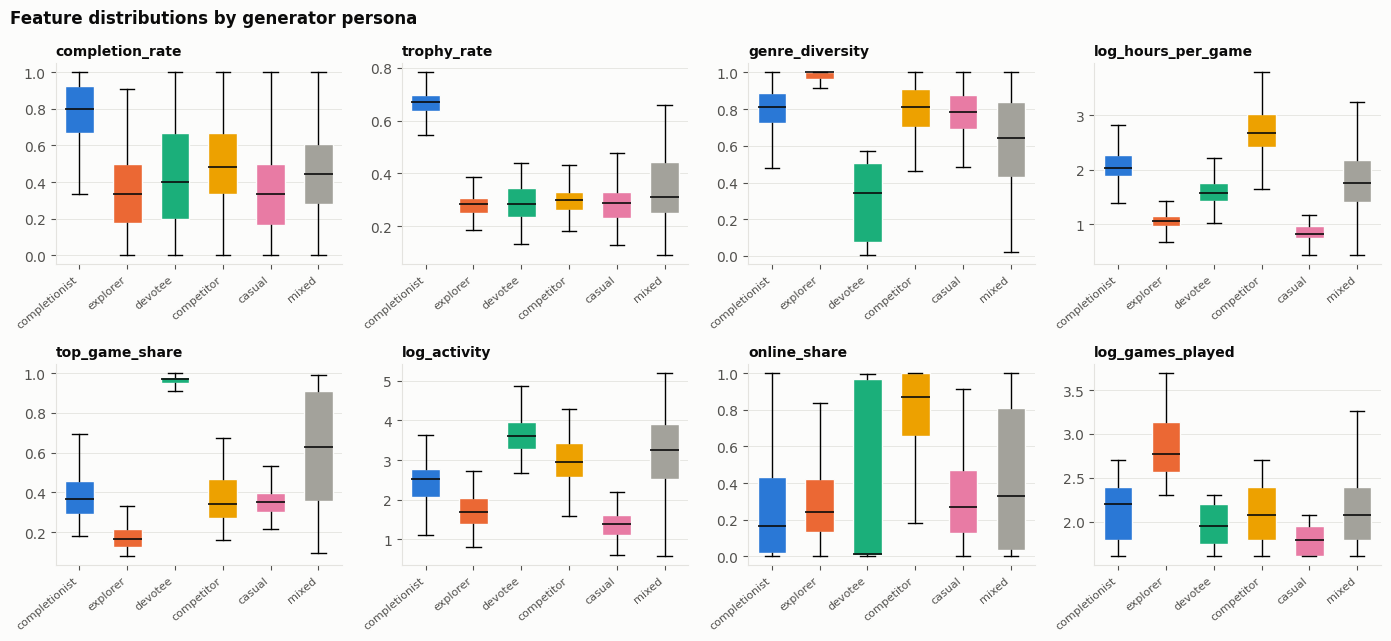

In [10]:
order = sim.PERSONA_NAMES + ["mixed"]
fig, axes = plt.subplots(2, 4, figsize=(14, 6.5))
for ax, feature in zip(axes.flat, FEATURE_NAMES):
    data = [X.loc[group == g, feature] for g in order]
    box = ax.boxplot(data, patch_artist=True, widths=0.6, showfliers=False,
                     medianprops={"color": INK, "linewidth": 1.2})
    for patch, g in zip(box["boxes"], order):
        patch.set(facecolor=PERSONA_COLORS[g], edgecolor=SURFACE, linewidth=1)
    ax.set_title(feature, fontsize=10)
    ax.set_xticks(range(1, len(order) + 1), order, rotation=40, ha="right", fontsize=8)
    ax.grid(axis="x", visible=False)
fig.suptitle("Feature distributions by generator persona", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "04_features_by_persona")

## 3. Choosing k

Inertia (elbow) and mean silhouette for k = 2..8, each with `KMeans(n_init=20, random_state=42)`.

In [11]:
KS = list(range(2, 9))

def sweep(z):
    # One KMeans per k, as the final model is fitted
    return {k: KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(z) for k in KS}

fits = sweep(Z)
k_table = pd.DataFrame({
    "inertia": {k: m.inertia_ for k, m in fits.items()},
    "silhouette": {k: silhouette_score(Z, m.labels_) for k, m in fits.items()},
}).rename_axis("k")
k_table.round(3)

,inertia,silhouette
k,,
2,3964.057,0.269
3,3015.913,0.288
4,2460.815,0.315
5,2099.936,0.309
6,1838.801,0.320
7,1745.932,0.286
8,1670.414,0.261


### k rule (fixed before looking at this run's results, applied mechanically)

> "If the best silhouettes are within 0.01 of each other, choose the largest of those k values
> where every cluster (a) differs from every other cluster by at least 0.5 SD in at least one
> feature and (b) holds at least 5% of players. Otherwise, choose the highest silhouette."

- *Within 0.01*: every k whose silhouette is at least (best silhouette − 0.01).
- *0.5 SD*: centres are compared in StandardScaler units, i.e. SDs of the training population.
  For each pair of clusters we take the largest feature gap; the closest pair must still reach 0.5.
- If several k are within 0.01 but none passes (a) and (b), the rule has no answer; we then fall
  back to the highest silhouette and say so.

In [12]:
K_TOL, MIN_SD_GAP, MIN_SHARE = 0.01, 0.5, 0.05

def rule_check(model, z):
    # (a) closest pair of centres, by its largest feature gap; (b) smallest cluster share
    c = model.cluster_centers_
    pairs = [(i, j, np.abs(c[i] - c[j]).max()) for i, j in itertools.combinations(range(len(c)), 2)]
    i, j, gap = min(pairs, key=lambda t: t[2])
    shares = np.bincount(model.labels_, minlength=len(c)) / len(z)
    return {
        "closest pair": f"{i}–{j}",
        "its largest gap (SD)": gap,
        "smallest cluster share": shares.min(),
        "(a) gap ≥ 0.5 SD": gap >= MIN_SD_GAP,
        "(b) share ≥ 5%": shares.min() >= MIN_SHARE,
    }

def choose_k(fits, z):
    sil = {k: silhouette_score(z, m.labels_) for k, m in fits.items()}
    best = max(sil.values())
    candidates = sorted(k for k in sil if sil[k] >= best - K_TOL)
    checks = pd.DataFrame({k: {"silhouette": sil[k], **rule_check(fits[k], z)} for k in candidates}).T.rename_axis("k")
    checks["passes"] = checks["(a) gap ≥ 0.5 SD"] & checks["(b) share ≥ 5%"]
    highest = max(sil, key=sil.get)
    if len(candidates) == 1:
        return highest, checks, "only one k within 0.01 → highest silhouette"
    passing = [k for k in candidates if checks.loc[k, "passes"]]
    if passing:
        return max(passing), checks, f"{len(candidates)} k within 0.01 → largest passing k"
    return highest, checks, "no candidate passes (a) and (b) → fallback: highest silhouette"

rule_k, rule_checks, rule_reason = choose_k(fits, Z)
print(f"chosen k = {rule_k} ({rule_reason})")
rule_checks.round(3)

chosen k = 6 (2 k within 0.01 → largest passing k)


,silhouette,closest pair,its largest gap (SD),smallest cluster share,(a) gap ≥ 0.5 SD,(b) share ≥ 5%,passes
k,,,,,,,
4,0.314792,2–3,1.834189,0.191904,True,True,True
6,0.319517,1–4,1.824917,0.094453,True,True,True


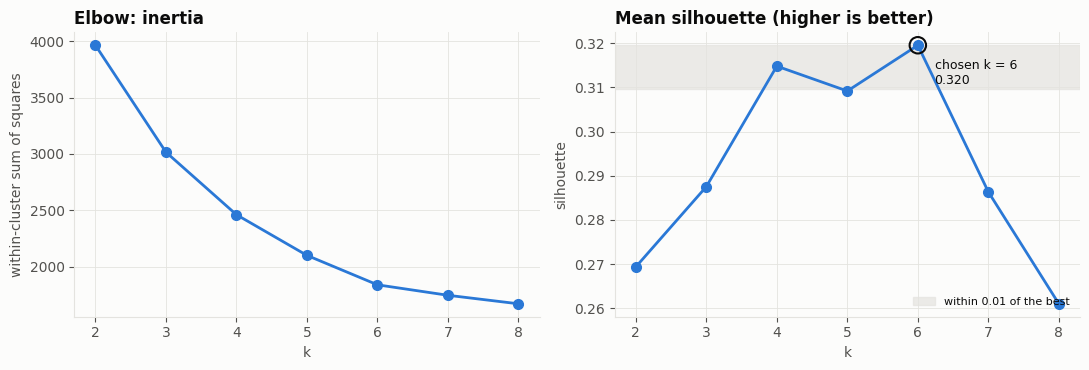

In [13]:
sil = k_table["silhouette"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.plot(KS, k_table["inertia"], color=SERIES[0], linewidth=2, marker="o", markersize=7)
a1.set_title("Elbow: inertia")
a1.set_xlabel("k"); a1.set_ylabel("within-cluster sum of squares")
a2.axhspan(sil.max() - K_TOL, sil.max(), color=GRID, alpha=0.7, zorder=0, label="within 0.01 of the best")
a2.plot(KS, sil, color=SERIES[0], linewidth=2, marker="o", markersize=7)
a2.scatter([rule_k], [sil[rule_k]], s=140, facecolor="none", edgecolor=INK, linewidth=1.5, zorder=3)
a2.annotate(f"chosen k = {rule_k}\n{sil[rule_k]:.3f}", (rule_k, sil[rule_k]),
            xytext=(12, -28), textcoords="offset points", color=INK, fontsize=9)
a2.set_title("Mean silhouette (higher is better)")
a2.set_xlabel("k"); a2.set_ylabel("silhouette")
a2.legend(loc="lower right", fontsize=8)
for ax in (a1, a2):
    ax.set_xticks(KS)
fig.tight_layout()
save(fig, "05_choose_k")

**Does the choice depend on the generator seed?** Repeat the sweep and the k rule on five other
simulated populations.

In [14]:
robust, robust_checks = {}, {}
for s in range(5):
    p_s = sim.generate_players(cal, seed=s)
    raw_s = pd.DataFrame([compute_features(p["games"]) for p in p_s], columns=FEATURE_NAMES).astype(float)
    x_s = raw_s.fillna(raw_s[IMPUTED_FEATURES].mean())
    z_s = StandardScaler().fit_transform(x_s)
    fits_s = sweep(z_s)
    k_s, checks_s, reason_s = choose_k(fits_s, z_s)
    row = {k: silhouette_score(z_s, m.labels_) for k, m in fits_s.items()}
    robust[f"generator seed {s}"] = {**row, "highest silhouette k": max(row, key=row.get), "rule k": k_s, "why": reason_s}
    robust_checks[f"generator seed {s}"] = checks_s
robust = pd.DataFrame(robust).T
robust

,2,3,4,5,6,7,8,highest silhouette k,rule k,why
generator seed 0,0.253894,0.307476,0.34248,0.329084,0.333054,0.313264,0.286752,4,6,2 k within 0.01 → largest passing k
generator seed 1,0.237217,0.280267,0.309835,0.307562,0.3188,0.284826,0.261322,6,6,2 k within 0.01 → largest passing k
generator seed 2,0.246762,0.300946,0.323338,0.312895,0.317315,0.294859,0.264578,4,6,2 k within 0.01 → largest passing k
generator seed 3,0.269554,0.288592,0.311695,0.31129,0.318222,0.290762,0.273839,6,6,3 k within 0.01 → largest passing k
generator seed 4,0.271922,0.29022,0.318018,0.321554,0.324284,0.298301,0.280001,6,6,3 k within 0.01 → largest passing k


In [15]:
# The rule's check for every candidate k on every generator seed
pd.concat(robust_checks, names=["population"]).round(3)

silhouette closest pair its largest gap (SD) smallest cluster share (a) gap ≥ 0.5 SD (b) share ≥ 5%  passes
population       k                                                                                                            
generator seed 0 4    0.34248          0–1             1.785348                 0.1994             True           True    True
                 6   0.333054          1–5             1.831255               0.058471             True           True    True
generator seed 1 4   0.309835          2–3             1.835788               0.197901             True           True    True
                 6     0.3188          4–5             1.807963               0.088456             True           True    True
generator seed 2 4   0.323338          1–3             1.804316               0.187406             True           True    True
                 6   0.317315          0–1             1.866487               0.068966             True           True    True
generator seed 3 4   0.311695          0–3             1.797111               0.187406             True           True    True
                 5    0.31129          0–1             1.810993               0.182909             True           True    True
                 6   0.318222          0–5             1.795665               0.071964             True           True    True
generator seed 4 4   0.318018          0–3             1.816314               0.209895             True           True    True
                 5   0.321554          0–1             1.802227               0.166417             True           True    True
                 6   0.324284          0–5             1.759729               0.067466             True           True    True

### k justification

Seed 42, starting persona parameters, 8 features, truncated library-size sampling.

- **Silhouette is 0.32: moderate overlap.** That is consistent with playstyle being a continuum
  rather than separate boxes; the app shows this to users through match scores (a % per
  archetype), not only a single label. k = 6 (0.320) and k = 4 (0.315) are within 0.01 of each
  other; k = 5 (0.309) misses the window by less than 0.001. So the rule applies.
- **Both candidates pass** (a) and (b): the closest pair of centres still differs by ≈ 1.8 SD in
  some feature, and the smallest cluster holds 9.4% (k = 6) / 19.2% (k = 4) of players. The rule
  takes the largest passing k: **k = 6**.
- **Same answer on every other generator seed**: the rule picks 6 on all five, although the
  highest silhouette alone would pick 4 on two of them.
- **The 0.5 SD condition of the k rule never decided anything for this data**: every closest pair
  of centres, for every candidate k on every generator seed, is ≥ 1.75 SD apart in some feature.
  The choice was decided by "largest k" and the 5% size check (on generator seed 0 the smallest
  k = 6 cluster is 5.8%, close to that limit).
- **Casual and explorer now mostly separate** (87 of 100 explorers in their own cluster, 13 with
  the casuals), after replacing clipped library sizes with truncated sampling.
- **Devotees still split by online share** (62 offline / 38 online), kept as two types.

In [16]:
K_OVERRIDE = None          # set an int here only after a reviewed decision
K = K_OVERRIDE or rule_k
print("k =", K)

k = 6


## 4. Fit the model

In [17]:
model = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(Z)
labels = model.labels_
print("silhouette:", round(silhouette_score(Z, labels), 3))
print("cluster sizes:", pd.Series(labels).value_counts().sort_index().to_dict())

silhouette: 0.32
cluster sizes: {0: 110, 1: 122, 2: 128, 3: 138, 4: 63, 5: 106}


## 5. Stability

Refit with 10 other seeds. Adjusted Rand Index (ARI) compares two labelings regardless of cluster
numbering: 1 = identical, 0 = chance.

In [18]:
runs = [KMeans(n_clusters=K, n_init=20, random_state=s).fit_predict(Z) for s in range(1, 11)]
pairwise = [adjusted_rand_score(a, b) for a, b in itertools.combinations(runs, 2)]
vs_model = [adjusted_rand_score(labels, r) for r in runs]
print(f"mean pairwise ARI over 10 seeds (45 pairs): {np.mean(pairwise):.3f}  (min {np.min(pairwise):.3f})")
print(f"mean ARI vs the fitted model:              {np.mean(vs_model):.3f}  (min {np.min(vs_model):.3f})")

mean pairwise ARI over 10 seeds (45 pairs): 1.000  (min 1.000)
mean ARI vs the fitted model:              1.000  (min 1.000)


> **Stable is not the same as valid.** High stability on simulated data shows the *pipeline* is
> stable: the same population gives the same clusters whatever the seed. It does not show the
> archetypes are valid descriptions of real players. Validation comes later, from the real-player
> (survey) test of the frozen model.

## 6. Interpret the clusters

Centres in **original units** (`scaler.inverse_transform`), next to the persona averages.

In [19]:
centres = pd.DataFrame(scaler.inverse_transform(model.cluster_centers_), columns=FEATURE_NAMES).rename_axis("cluster")
centres["players"] = pd.Series(labels).value_counts().sort_index()
centres.round(2)

,completion_rate,trophy_rate,genre_diversity,log_hours_per_game,top_game_share,log_activity,online_share,log_games_played,players
cluster,,,,,,,,,
0,0.41,0.29,0.33,1.76,0.94,3.81,0.02,1.98,110
1,0.46,0.30,0.80,2.65,0.39,3.06,0.79,2.13,122
2,0.78,0.63,0.80,2.03,0.40,2.44,0.27,2.14,128
3,0.37,0.29,0.78,0.94,0.37,1.42,0.32,1.85,138
4,0.45,0.29,0.31,1.71,0.92,3.73,0.96,2.00,63
5,0.35,0.28,0.97,1.13,0.18,1.99,0.32,2.94,106


In [20]:
persona_means = X.groupby(group).mean().loc[order]
persona_means.round(2)

,completion_rate,trophy_rate,genre_diversity,log_hours_per_game,top_game_share,log_activity,online_share,log_games_played
group,,,,,,,,
completionist,0.78,0.67,0.80,2.09,0.39,2.44,0.26,2.14
explorer,0.35,0.28,0.97,1.05,0.17,1.71,0.29,2.85
devotee,0.44,0.28,0.30,1.60,0.97,3.68,0.38,1.94
competitor,0.48,0.30,0.79,2.71,0.37,2.95,0.79,2.09
casual,0.35,0.28,0.78,0.85,0.36,1.37,0.33,1.79
mixed,0.46,0.34,0.62,1.81,0.62,3.18,0.41,2.17


In [21]:
composition = pd.crosstab(group, pd.Series(labels, name="cluster")).loc[order]
composition

cluster,0,1,2,3,4,5
group,,,,,,
completionist,0,1,99,0,0,0
explorer,0,0,0,13,0,87
devotee,62,0,0,0,38,0
competitor,1,96,2,1,0,0
casual,0,0,1,99,0,0
mixed,47,25,26,25,25,19


In [22]:
# Suggest a name per cluster: the pure persona whose average is nearest the centre (scaled space)
persona_z = pd.DataFrame(scaler.transform(persona_means.loc[sim.PERSONA_NAMES]), index=sim.PERSONA_NAMES)
dist = pd.DataFrame(
    [[np.linalg.norm(c - persona_z.loc[p]) for p in sim.PERSONA_NAMES] for c in model.cluster_centers_],
    columns=sim.PERSONA_NAMES,
).rename_axis("cluster")
suggested = dist.idxmin(axis=1).rename("nearest persona")
dupes = suggested[suggested.duplicated(keep=False)]
print("nearest persona per cluster:", suggested.to_dict())
if not dupes.empty:
    print("!! several clusters share a nearest persona:", dupes.to_dict())
dist.round(2)

nearest persona per cluster: {0: 'devotee', 1: 'competitor', 2: 'completionist', 3: 'casual', 4: 'devotee', 5: 'explorer'}
!! several clusters share a nearest persona: {0: 'devotee', 4: 'devotee'}


,completionist,explorer,devotee,competitor,casual
cluster,,,,,
0,4.07,4.63,1.03,3.71,3.84
1,3.15,3.48,3.36,0.17,3.39
2,0.24,3.64,3.96,3.00,3.45
3,3.51,2.32,3.63,3.25,0.20
4,4.41,4.86,1.63,3.09,4.07
5,3.79,0.36,4.58,3.42,2.68


### Cluster names — confirmed by the team

k = 6 and these names were confirmed at the review checkpoint. The descriptions are the one-line
texts the app shows; both are exported with the model.

In [23]:
# Confirmed by the team; exported with the model
CLUSTER_NAMES = {
    0: "Devotee",         # one game is 94% of hours, offline (online share 0.02)
    1: "Competitor",      # online share 0.79, longest sessions
    2: "Completionist",   # completion 0.78, trophies 0.63
    3: "Casual",          # lowest hours per game and per month, fewest games
    4: "The Main",        # one game is 92% of hours, and it is online (online share 0.96)
    5: "Explorer",        # most games (ln 2.94 ≈ 19), genre diversity 0.97, top game only 18%
}
CLUSTER_DESCRIPTIONS = {
    "Completionist": "You finish what you start and chase the trophies.",
    "Explorer": "Always trying something new, across lots of genres.",
    "Competitor": "Online, competitive, and in it for the long sessions.",
    "The Main": "One online game has most of your hours.",
    "Devotee": "One game you keep coming back to, over and over.",
    "Casual": "You play when life gives you time.",
}
assert sorted(CLUSTER_NAMES) == list(range(K)), "CLUSTER_NAMES must cover every cluster"
assert set(CLUSTER_DESCRIPTIONS) == set(CLUSTER_NAMES.values()), "every name needs a description"

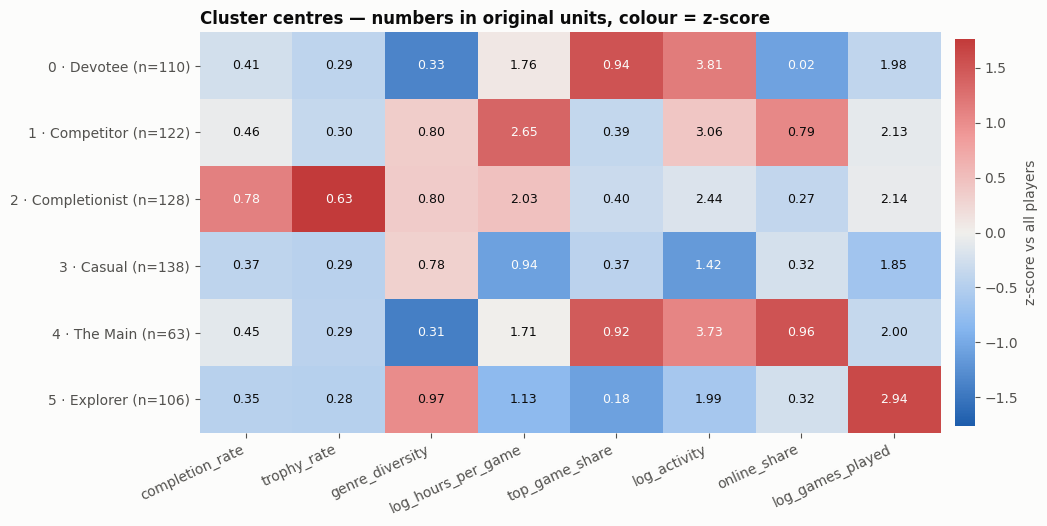

In [24]:
zc = pd.DataFrame(model.cluster_centers_, columns=FEATURE_NAMES)
fig, ax = plt.subplots(figsize=(10, 0.6 * K + 1.6))
lim = np.abs(zc.values).max()
im = ax.imshow(zc.values, cmap=DIVERGING, vmin=-lim, vmax=lim, aspect="auto")
for i in range(K):
    for j in range(len(FEATURE_NAMES)):
        z = zc.iloc[i, j]
        ax.text(j, i, f"{centres.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9,
                color=SURFACE if abs(z) > 0.6 * lim else INK)
ax.set_xticks(range(len(FEATURE_NAMES)), FEATURE_NAMES, rotation=25, ha="right")
ax.set_yticks(range(K), [f"{i} · {CLUSTER_NAMES[i]} (n={centres['players'][i]})" for i in range(K)])
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cb.set_label("z-score vs all players", color=INK2)
cb.outline.set_visible(False)
ax.set_title("Cluster centres — numbers in original units, colour = z-score")
save(fig, "06_cluster_centres")

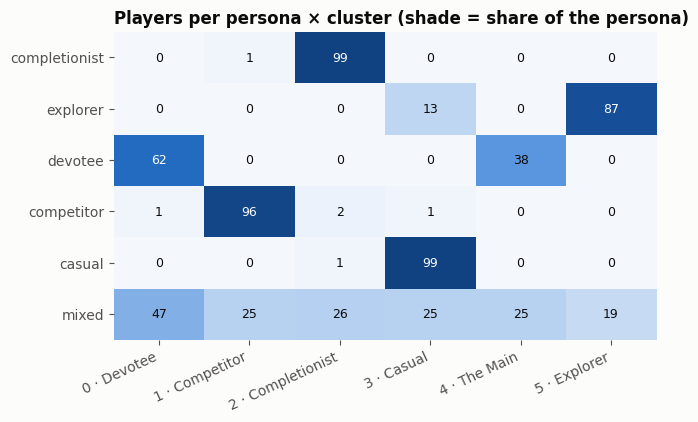

In [25]:
share = composition.div(composition.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(7, 4))
ax.imshow(share.values, cmap=LinearSegmentedColormap.from_list("blue", ["#f4f8fd", "#2a78d6", "#104281"]),
          vmin=0, vmax=1, aspect="auto")
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        ax.text(j, i, composition.iloc[i, j], ha="center", va="center", fontsize=9,
                color=SURFACE if share.iloc[i, j] > 0.55 else INK)
ax.set_xticks(range(K), [f"{i} · {CLUSTER_NAMES[i]}" for i in range(K)], rotation=25, ha="right")
ax.set_yticks(range(len(order)), order)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Players per persona × cluster (shade = share of the persona)")
save(fig, "07_persona_by_cluster")

## 7. Sanity check against the generator's labels

> **Sanity check only, not validation.** The personas were designed by us, so agreement only shows
> the pipeline recovers structure we put in; it says nothing about real players. Real validation
> comes later, from survey players scored by the frozen model.

In [26]:
ari_pure = adjusted_rand_score(group[is_pure], labels[is_pure])
print(f"ARI clusters vs persona labels (pure players only): {ari_pure:.3f}")

ARI clusters vs persona labels (pure players only): 0.845


## 8. 2D PCA view

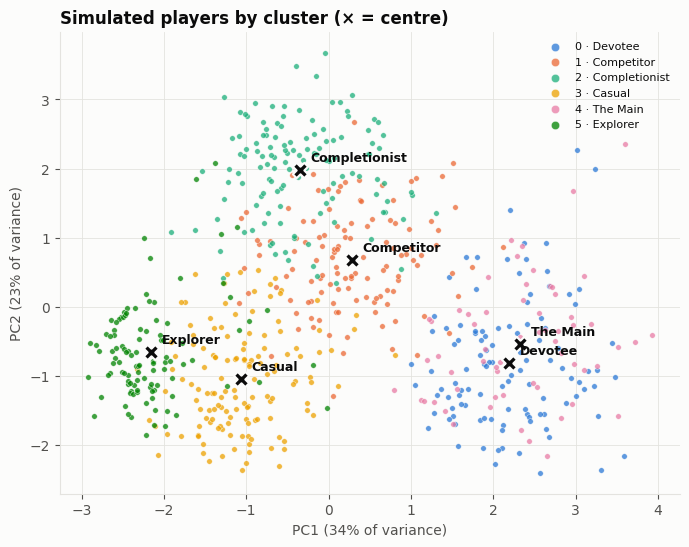

In [27]:
pca = PCA(n_components=2, random_state=SEED).fit(Z)
P2 = pca.transform(Z)
C2 = pca.transform(model.cluster_centers_)
ev = pca.explained_variance_ratio_

def pca_axes(ax, title):
    ax.set_title(title)
    ax.set_xlabel(f"PC1 ({ev[0]:.0%} of variance)")
    ax.set_ylabel(f"PC2 ({ev[1]:.0%} of variance)")

fig, ax = plt.subplots(figsize=(8, 6))
for c in range(K):
    m = labels == c
    ax.scatter(P2[m, 0], P2[m, 1], s=16, color=SERIES[c], alpha=0.75, edgecolor=SURFACE, linewidth=0.4,
               label=f"{c} · {CLUSTER_NAMES[c]}")
ax.scatter(C2[:, 0], C2[:, 1], s=120, color=INK, marker="X", edgecolor=SURFACE, linewidth=1.5, zorder=3)
for c in range(K):
    ax.annotate(CLUSTER_NAMES[c], C2[c], xytext=(8, 6), textcoords="offset points", fontsize=9,
                fontweight="bold", color=INK)
ax.legend(loc="best", fontsize=8, markerscale=1.5)
pca_axes(ax, "Simulated players by cluster (× = centre)")
save(fig, "08_pca_clusters")

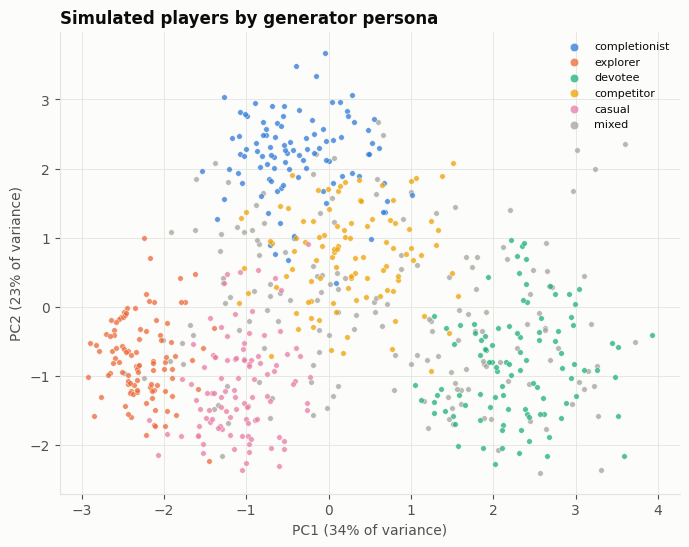

In [28]:
fig, ax = plt.subplots(figsize=(8, 6))
for g in order:
    m = (group == g).to_numpy()
    ax.scatter(P2[m, 0], P2[m, 1], s=16, color=PERSONA_COLORS[g], alpha=0.75, edgecolor=SURFACE,
               linewidth=0.4, label=g, zorder=1 if g == "mixed" else 2)
ax.legend(loc="best", fontsize=8, markerscale=1.5)
pca_axes(ax, "Simulated players by generator persona")
save(fig, "09_pca_personas")

In [29]:
loadings = pd.DataFrame(pca.components_.T, index=FEATURE_NAMES, columns=["PC1", "PC2"])
loadings.round(2)

,PC1,PC2
completion_rate,0.04,0.58
trophy_rate,-0.04,0.60
genre_diversity,-0.54,0.18
log_hours_per_game,0.26,0.47
top_game_share,0.56,-0.16
log_activity,0.48,0.11
online_share,0.08,0.10
log_games_played,-0.31,0.01


## Summary

In [30]:
print(f"k = {K} (silhouette {silhouette_score(Z, labels):.3f}); "
      f"stability mean pairwise ARI {np.mean(pairwise):.3f}; "
      f"sanity ARI vs personas {ari_pure:.3f}")
centres.round(2).assign(name=pd.Series(CLUSTER_NAMES))

k = 6 (silhouette 0.320); stability mean pairwise ARI 1.000; sanity ARI vs personas 0.845


,completion_rate,trophy_rate,genre_diversity,log_hours_per_game,top_game_share,log_activity,online_share,log_games_played,players,name
cluster,,,,,,,,,,
0,0.41,0.29,0.33,1.76,0.94,3.81,0.02,1.98,110,Devotee
1,0.46,0.30,0.80,2.65,0.39,3.06,0.79,2.13,122,Competitor
2,0.78,0.63,0.80,2.03,0.40,2.44,0.27,2.14,128,Completionist
3,0.37,0.29,0.78,0.94,0.37,1.42,0.32,1.85,138,Casual
4,0.45,0.29,0.31,1.71,0.92,3.73,0.96,2.00,63,The Main
5,0.35,0.28,0.97,1.13,0.18,1.99,0.32,2.94,106,Explorer


## 9. Freeze and export the model

The model is written as **JSON, not pickle**: everything the service needs to assign a user to
the nearest centre, and nothing else. The service never retrains. `centre_scaled` is in
StandardScaler units; `centre` is the same point in original units (for the reasons texts).

In [31]:
import json
from datetime import datetime, timezone

MODEL_VERSION = "1.0.0"
MODEL_PATH = REPO_DIR / "models" / "archetype_model.json"
MODEL_PATH.parent.mkdir(exist_ok=True)

shares = np.bincount(labels, minlength=K) / len(labels)
export = {
    "version": MODEL_VERSION,
    "trained_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "seed": SEED,
    "min_games": MIN_GAMES,
    "k": int(K),
    "silhouette": round(float(silhouette_score(Z, labels)), 4),
    "features": FEATURE_NAMES,
    "scoring": {
        "method": "softmax of negative Euclidean distances (scaled space) / temperature; "
                  "whole-number percentages by largest remainder",
        "temperature": 0.75,
    },
    "imputation": {f: float(IMPUTE[f]) for f in IMPUTED_FEATURES},
    "scaler": {"mean": scaler.mean_.tolist(), "scale": scaler.scale_.tolist()},
    "clusters": [
        {
            "id": c,
            "name": CLUSTER_NAMES[c],
            "description": CLUSTER_DESCRIPTIONS[CLUSTER_NAMES[c]],
            "centre_scaled": model.cluster_centers_[c].tolist(),
            "centre": dict(zip(FEATURE_NAMES, centres.loc[c, FEATURE_NAMES].astype(float).tolist())),
            "training_share": round(float(shares[c]), 4),
        }
        for c in range(K)
    ],
    "training": {
        "players": len(players),
        "n_per_persona": 100,
        "mix_share": 0.25,
        "kmeans": {"n_init": 20, "random_state": SEED},
        "k_rule": "silhouettes within 0.01 -> largest k whose clusters all differ by >= 0.5 SD "
                  "in some feature and hold >= 5% of players; else highest silhouette",
        "stability_mean_pairwise_ari": round(float(np.mean(pairwise)), 4),
        "persona_sanity_ari": round(float(ari_pure), 4),
        "calibration": "Steam 200k: play rows > 0h, hours capped at the 99th pct, users with >= 5 games",
    },
}
MODEL_PATH.write_text(json.dumps(export, indent=2) + "\n")
print("wrote", MODEL_PATH.relative_to(REPO_DIR), f"({MODEL_PATH.stat().st_size} bytes)")

wrote models/archetype_model.json (6322 bytes)


In [32]:
# Round trip: the JSON alone must reproduce the fitted model's assignments
saved = json.loads(MODEL_PATH.read_text())
assert saved["features"] == FEATURE_NAMES
x = raw.fillna(pd.Series(saved["imputation"]))[saved["features"]].to_numpy()
z = (x - np.array(saved["scaler"]["mean"])) / np.array(saved["scaler"]["scale"])
c = np.array([cl["centre_scaled"] for cl in saved["clusters"]])
nearest = np.argmin(((z[:, None, :] - c[None, :, :]) ** 2).sum(axis=2), axis=1)
assert (nearest == labels).all(), "JSON assignments differ from the fitted model"
print(f"round trip OK: all {len(labels)} training players get the same cluster from the JSON")
pd.DataFrame([{k: cl[k] for k in ("id", "name", "description", "training_share")} for cl in saved["clusters"]])

round trip OK: all 667 training players get the same cluster from the JSON


,id,name,description,training_share
0,0,Devotee,"One game you keep coming back to, over and over.",0.1649
1,1,Competitor,"Online, competitive, and in it for the long se...",0.1829
2,2,Completionist,You finish what you start and chase the trophies.,0.1919
3,3,Casual,You play when life gives you time.,0.2069
4,4,The Main,One online game has most of your hours.,0.0945
5,5,Explorer,"Always trying something new, across lots of ge...",0.1589
